In [1]:
!wget http://example.com/energy.zip
!unzip energy.zip

--2024-01-23 11:45:54--  http://example.com/energy.zip
Resolving example.com (example.com)... 93.184.216.34, 2606:2800:220:1:248:1893:25c8:1946
Connecting to example.com (example.com)|93.184.216.34|:80... connected.
HTTP request sent, awaiting response... 404 Not Found
2024-01-23 11:45:54 ERROR 404: Not Found.

Archive:  energy.zip
  inflating: AEP_hourly.csv          
  inflating: COMED_hourly.csv        
  inflating: DAYTON_hourly.csv       
  inflating: DEOK_hourly.csv         
  inflating: DOM_hourly.csv          
  inflating: DUQ_hourly.csv          
  inflating: EKPC_hourly.csv         
  inflating: FE_hourly.csv           
  inflating: NI_hourly.csv           
  inflating: PJME_hourly.csv         
  inflating: PJMW_hourly.csv         
  inflating: PJM_Load_hourly.csv     
  inflating: est_hourly.paruqet      
  inflating: pjm_hourly_est.csv      


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Dense, LSTM
from keras.optimizers import Adam

In [3]:
df1 = pd.read_csv('AEP_hourly.csv')

In [4]:
df2 = pd.read_csv('COMED_hourly.csv')

In [5]:
df3 = pd.read_csv('DAYTON_hourly.csv')
df4 = pd.read_csv('DEOK_hourly.csv')
df5 = pd.read_csv('DOM_hourly.csv')
df6 = pd.read_csv('DUQ_hourly.csv')
df7 = pd.read_csv('EKPC_hourly.csv')
df8 = pd.read_csv('FE_hourly.csv')
df9 = pd.read_csv('NI_hourly.csv')
df10 = pd.read_csv('PJME_hourly.csv')
df11 = pd.read_csv('PJMW_hourly.csv')
df12 = pd.read_csv('PJM_Load_hourly.csv')
df13 = pd.read_csv('pjm_hourly_est.csv')

In [6]:
df1,df2,df3,df4,df5,df6,df7,df8,df9,df10,df11,df12,df13.head()

(                   Datetime   AEP_MW
 0       2004-12-31 01:00:00  13478.0
 1       2004-12-31 02:00:00  12865.0
 2       2004-12-31 03:00:00  12577.0
 3       2004-12-31 04:00:00  12517.0
 4       2004-12-31 05:00:00  12670.0
 ...                     ...      ...
 121268  2018-01-01 20:00:00  21089.0
 121269  2018-01-01 21:00:00  20999.0
 121270  2018-01-01 22:00:00  20820.0
 121271  2018-01-01 23:00:00  20415.0
 121272  2018-01-02 00:00:00  19993.0
 
 [121273 rows x 2 columns],
                   Datetime  COMED_MW
 0      2011-12-31 01:00:00    9970.0
 1      2011-12-31 02:00:00    9428.0
 2      2011-12-31 03:00:00    9059.0
 3      2011-12-31 04:00:00    8817.0
 4      2011-12-31 05:00:00    8743.0
 ...                    ...       ...
 66492  2018-01-01 20:00:00   13858.0
 66493  2018-01-01 21:00:00   13758.0
 66494  2018-01-01 22:00:00   13627.0
 66495  2018-01-01 23:00:00   13336.0
 66496  2018-01-02 00:00:00   12816.0
 
 [66497 rows x 2 columns],
                    Datetime 

In [7]:
df1,df2,df3,df4,df5,df6,df7,df8,df9,df10,df11,df12,df13.isnull().sum()

(                   Datetime   AEP_MW
 0       2004-12-31 01:00:00  13478.0
 1       2004-12-31 02:00:00  12865.0
 2       2004-12-31 03:00:00  12577.0
 3       2004-12-31 04:00:00  12517.0
 4       2004-12-31 05:00:00  12670.0
 ...                     ...      ...
 121268  2018-01-01 20:00:00  21089.0
 121269  2018-01-01 21:00:00  20999.0
 121270  2018-01-01 22:00:00  20820.0
 121271  2018-01-01 23:00:00  20415.0
 121272  2018-01-02 00:00:00  19993.0
 
 [121273 rows x 2 columns],
                   Datetime  COMED_MW
 0      2011-12-31 01:00:00    9970.0
 1      2011-12-31 02:00:00    9428.0
 2      2011-12-31 03:00:00    9059.0
 3      2011-12-31 04:00:00    8817.0
 4      2011-12-31 05:00:00    8743.0
 ...                    ...       ...
 66492  2018-01-01 20:00:00   13858.0
 66493  2018-01-01 21:00:00   13758.0
 66494  2018-01-01 22:00:00   13627.0
 66495  2018-01-01 23:00:00   13336.0
 66496  2018-01-02 00:00:00   12816.0
 
 [66497 rows x 2 columns],
                    Datetime 

In [8]:
dfs = [df1, df2, df3, df4, df5, df6, df7, df8, df9, df10, df11, df12, df13]
df_combined = pd.concat(dfs, axis=1)

In [9]:
print("Jumlah Data Null:")
print(df_combined.isnull().sum())

Jumlah Data Null:
Datetime        56989
AEP_MW          56989
Datetime       111765
COMED_MW       111765
Datetime        56987
DAYTON_MW       56987
Datetime       120523
DEOK_MW        120523
Datetime        62073
DOM_MW          62073
Datetime        59194
DUQ_MW          59194
Datetime       132928
EKPC_MW        132928
Datetime       115388
FE_MW          115388
Datetime       119812
NI_MW          119812
Datetime        32896
PJME_MW         32896
Datetime        35056
PJMW_MW         35056
Datetime       145366
PJM_Load_MW    145366
Datetime            0
AEP             56989
COMED          111765
DAYTON          56987
DEOK           120523
DOM             62073
DUQ             59194
EKPC           132928
FE             115388
NI             119812
PJME            32896
PJMW            35056
PJM_Load       145366
dtype: int64


In [10]:
df_combined = df_combined.fillna(df_combined.mean())


<ipython-input-10-4bfb93e9da16>:1: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  df_combined = df_combined.fillna(df_combined.mean())


In [11]:
df_combined['Total'] = df_combined.sum(axis=1)
df = df_combined[['Total']]

<ipython-input-11-1d47e7702fb8>:1: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  df_combined['Total'] = df_combined.sum(axis=1)


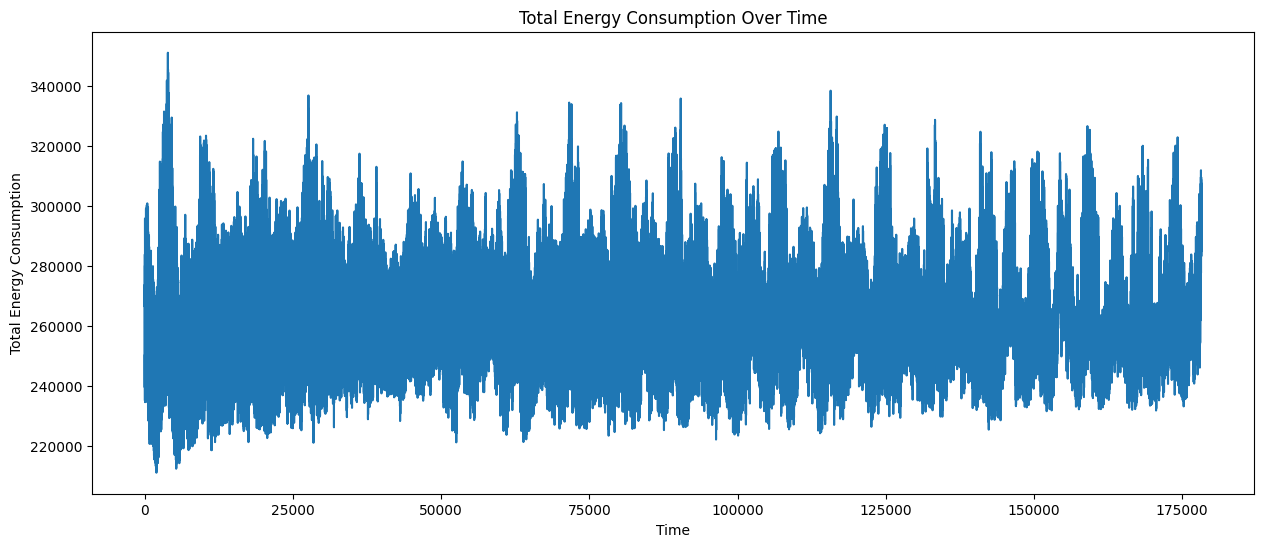

In [12]:
plt.figure(figsize=(15, 6))
plt.plot(df.index, df['Total'])
plt.title('Total Energy Consumption Over Time')
plt.xlabel('Time')
plt.ylabel('Total Energy Consumption')
plt.show()

In [13]:
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df)

In [14]:
train_size = int(len(df_scaled) * 0.8)
train_data, val_data = df_scaled[0:train_size, :], df_scaled[train_size:len(df_scaled), :]

In [18]:
def create_dataset(dataset, time_steps=1):
    dataX, dataY = [], []
    for i in range(len(dataset) - time_steps):
        a = dataset[i:(i + time_steps), 0]
        dataX.append(a)
        dataY.append(dataset[i + time_steps, 0])
    return np.array(dataX), np.array(dataY)

In [19]:
time_steps = 10

In [20]:
X_train, y_train = create_dataset(train_data, time_steps)
X_val, y_val = create_dataset(val_data, time_steps)

In [21]:
X_train = np.reshape(X_train, (X_train.shape[0], 1, X_train.shape[1]))
X_val = np.reshape(X_val, (X_val.shape[0], 1, X_val.shape[1]))

In [25]:
model = Sequential()
model.add(LSTM(units=50, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(units=1))
optimizer = Adam(learning_rate=0.001)
model.compile(optimizer=optimizer,loss='mean_squared_error', metrics=["mae"])


In [26]:
from keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

In [30]:
history = model.fit(X_train, y_train, epochs=30, batch_size=32, validation_data=(X_val, y_val), callbacks=[early_stopping])


Epoch 1/30
4457/4457 [==============================] - 16s 4ms/step - loss: 2.6531e-04 - mae: 0.0112 - val_loss: 3.1657e-04 - val_mae: 0.0111
Epoch 2/30
4457/4457 [==============================] - 16s 4ms/step - loss: 2.6377e-04 - mae: 0.0111 - val_loss: 4.1198e-04 - val_mae: 0.0151
Epoch 3/30
4457/4457 [==============================] - 15s 3ms/step - loss: 2.6440e-04 - mae: 0.0111 - val_loss: 3.0735e-04 - val_mae: 0.0111
Epoch 4/30
4457/4457 [==============================] - 17s 4ms/step - loss: 2.6265e-04 - mae: 0.0111 - val_loss: 3.9848e-04 - val_mae: 0.0148
Epoch 5/30
4457/4457 [==============================] - 16s 4ms/step - loss: 2.6137e-04 - mae: 0.0110 - val_loss: 2.9596e-04 - val_mae: 0.0105
Epoch 6/30
4457/4457 [==============================] - 19s 4ms/step - loss: 2.5999e-04 - mae: 0.0110 - val_loss: 3.4519e-04 - val_mae: 0.0120
Epoch 7/30
4457/4457 [==============================] - 17s 4ms/step - loss: 2.6133e-04 - mae: 0.0110 - val_loss: 2.9025e-04 - val_mae: 0.0104

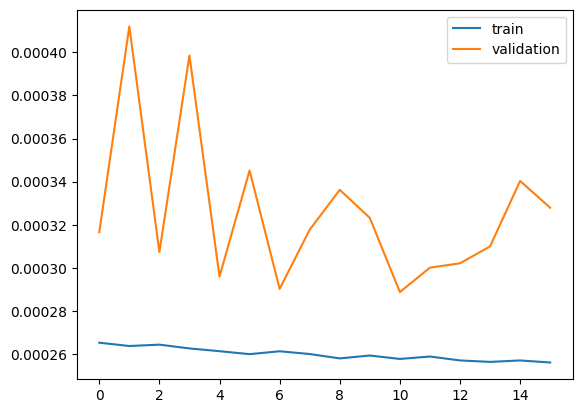

In [31]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.legend()
plt.show()

In [32]:
train_predict = model.predict(X_train)
val_predict = model.predict(X_val)


1114/1114 [==============================] - 2s 2ms/step


In [33]:
train_predict = scaler.inverse_transform(train_predict)
y_train = scaler.inverse_transform([y_train])
val_predict = scaler.inverse_transform(val_predict)
y_val = scaler.inverse_transform([y_val])

In [34]:
train_score = mean_absolute_error(y_train[0], train_predict[:, 0])
val_score = mean_absolute_error(y_val[0], val_predict[:, 0])

In [35]:
print(f'Training MAE: {train_score:.2f} units')
print(f'Validation MAE: {val_score:.2f} units')


Training MAE: 1460.89 units
Validation MAE: 1438.33 units
